<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Custom embedddings con Gensim



### Objetivo
El objetivo es utilizar documentos / corpus para crear embeddings de palabras basado en ese contexto. Se utilizará canciones de bandas para generar los embeddings, es decir, que los vectores tendrán la forma en función de como esa banda haya utilizado las palabras en sus canciones.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import multiprocessing
try:
  from gensim.models import Word2Vec
except:
  !pip install gensim
  from gensim.models import Word2Vec

### Datos
Utilizaremos como dataset canciones de bandas de habla inglesa.

In [2]:
# Descargar la carpeta de dataset
import os
import platform
if os.access('./songs_dataset', os.F_OK) is False:
    if os.access('songs_dataset.zip', os.F_OK) is False:
        if platform.system() == 'Windows':
            !curl https://raw.githubusercontent.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/main/datasets/songs_dataset.zip -o songs_dataset.zip
        else:
            !wget songs_dataset.zip https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/raw/main/datasets/songs_dataset.zip
    !unzip -q songs_dataset.zip
else:
    print("El dataset ya se encuentra descargado")

El dataset ya se encuentra descargado


In [3]:
# Posibles bandas
os.listdir("./songs_dataset/")

['lorde.txt',
 'bruno-mars.txt',
 'prince.txt',
 'bob-marley.txt',
 'amy-winehouse.txt',
 'adele.txt',
 'lady-gaga.txt',
 'nickelback.txt',
 'lin-manuel-miranda.txt',
 'dickinson.txt',
 'joni-mitchell.txt',
 'r-kelly.txt',
 'janisjoplin.txt',
 'johnny-cash.txt',
 'disney.txt',
 'Kanye_West.txt',
 'dj-khaled.txt',
 'bjork.txt',
 'blink-182.txt',
 'cake.txt',
 'rihanna.txt',
 'notorious-big.txt',
 'kanye-west.txt',
 'Lil_Wayne.txt',
 'drake.txt',
 'bieber.txt',
 'beatles.txt',
 'bob-dylan.txt',
 'ludacris.txt',
 'bruce-springsteen.txt',
 'dr-seuss.txt',
 'alicia-keys.txt',
 'dolly-parton.txt',
 'nicki-minaj.txt',
 'leonard-cohen.txt',
 'jimi-hendrix.txt',
 'nursery_rhymes.txt',
 'radiohead.txt',
 'paul-simon.txt',
 'michael-jackson.txt',
 'nirvana.txt',
 'eminem.txt',
 'britney-spears.txt',
 'al-green.txt',
 'lil-wayne.txt',
 'notorious_big.txt',
 'patti-smith.txt',
 'missy-elliott.txt',
 'kanye.txt']

In [4]:
# Armar el dataset utilizando salto de línea para separar las oraciones/docs
df = pd.read_csv('songs_dataset/beatles.txt', sep='/n', header=None)
df.head()

/tmp/ipykernel_42301/3849064916.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support separators > 1 char, including regex separators; you can avoid this warning by specifying engine='python'.
  df = pd.read_csv('songs_dataset/beatles.txt', sep='/n', header=None)


,0
0,"Yesterday, all my troubles seemed so far away"
1,Now it looks as though they're here to stay
2,"Oh, I believe in yesterday Suddenly, I'm not h..."
3,There's a shadow hanging over me.
4,"Oh, yesterday came suddenly Why she had to go ..."


In [5]:
print("Cantidad de documentos:", df.shape[0])

Cantidad de documentos: 1846


### 1 - Preprocesamiento

In [6]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

sentence_tokens = []
# Recorrer todas las filas y transformar las oraciones
# en una secuencia de palabras (esto podría realizarse con NLTK o spaCy también)
for _, row in df[:None].iterrows():
    sentence_tokens.append(text_to_word_sequence(row[0]))

I0000 00:00:1794343130.992570   42301 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794343131.035219   42301 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794343131.748563   42301 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [7]:
# Demos un vistazo
sentence_tokens[:2]

[['yesterday', 'all', 'my', 'troubles', 'seemed', 'so', 'far', 'away'],
 ['now', 'it', 'looks', 'as', 'though', "they're", 'here', 'to', 'stay']]

### 2 - Crear los vectores (word2vec)

In [8]:
from gensim.models.callbacks import CallbackAny2Vec
# Durante el entrenamiento gensim por defecto no informa el "loss" en cada época
# Sobrecargamos el callback para poder tener esta información
class callback(CallbackAny2Vec):
    """
    Callback to print loss after each epoch
    """
    def __init__(self):
        self.epoch = 0

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        if self.epoch == 0:
            print('Loss after epoch {}: {}'.format(self.epoch, loss))
        else:
            print('Loss after epoch {}: {}'.format(self.epoch, loss- self.loss_previous_step))
        self.epoch += 1
        self.loss_previous_step = loss

In [9]:
# Crearmos el modelo generador de vectores
# En este caso utilizaremos la estructura modelo Skipgram
w2v_model = Word2Vec(min_count=5,    # frecuencia mínima de palabra para incluirla en el vocabulario
                     window=2,       # cant de palabras antes y desp de la predicha
                     vector_size=300,       # dimensionalidad de los vectores
                     negative=20,    # cantidad de negative samples... 0 es no se usa
                     workers=1,      # si tienen más cores pueden cambiar este valor
                     sg=1)           # modelo 0:CBOW  1:skipgram

In [10]:
# Obtener el vocabulario con los tokens
w2v_model.build_vocab(sentence_tokens)

In [11]:
# Cantidad de filas/docs encontradas en el corpus
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)

Cantidad de docs en el corpus: 1846


In [12]:
# Cantidad de words encontradas en el corpus
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Cantidad de words distintas en el corpus: 445


### 3 - Entrenar embeddings

In [13]:
# Entrenamos el modelo generador de vectores
# Utilizamos nuestro callback
w2v_model.train(sentence_tokens,
                 total_examples=w2v_model.corpus_count,
                 epochs=20,
                 compute_loss = True,
                 callbacks=[callback()]
                 )

Loss after epoch 0: 113045.25
Loss after epoch 1: 65966.625
Loss after epoch 2: 65935.046875
Loss after epoch 3: 65718.328125
Loss after epoch 4: 63875.03125
Loss after epoch 5: 64160.8125
Loss after epoch 6: 64080.3125


Loss after epoch 7: 64814.96875


Loss after epoch 8: 62632.5
Loss after epoch 9: 60452.875
Loss after epoch 10: 59839.875
Loss after epoch 11: 58883.875
Loss after epoch 12: 57716.125
Loss after epoch 13: 56494.1875
Loss after epoch 14: 55817.5625


Loss after epoch 15: 55843.1875


Loss after epoch 16: 51722.3125
Loss after epoch 17: 49858.125
Loss after epoch 18: 49592.375
Loss after epoch 19: 48960.0


(156986, 287740)

### 4 - Ensayar

In [14]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["darling"], topn=10)

[('pretty', 0.8954238295555115),
 ('sleep', 0.8665637969970703),
 ('help', 0.8439353108406067),
 ('cry', 0.8351286053657532),
 ('not', 0.8309641480445862),
 ('try', 0.8276920318603516),
 ('peace', 0.8144835233688354),
 ('little', 0.8140542507171631),
 ('twist', 0.8123894929885864),
 ('seems', 0.8079566359519958)]

In [15]:
# Palabras que MENOS se relacionan con...:
w2v_model.wv.most_similar(negative=["love"], topn=10)

[('shake', -0.2287309318780899),
 ('four', -0.23302660882472992),
 ('five', -0.23746736347675323),
 ('six', -0.23784852027893066),
 ('bang', -0.24833035469055176),
 ('our', -0.2553912103176117),
 ('day', -0.2689830958843231),
 ('going', -0.2692137360572815),
 ('here', -0.2699104845523834),
 ('three', -0.2839003801345825)]

In [16]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["four"], topn=10)

[('five', 0.9813724756240845),
 ('three', 0.9745777249336243),
 ('six', 0.9710812568664551),
 ('seven', 0.9584368467330933),
 ('two', 0.9517239332199097),
 ('sixty', 0.8990397453308105),
 ('one', 0.795121431350708),
 ('crying', 0.7946274280548096),
 ('us', 0.7740067839622498),
 ("i'm", 0.7508398294448853)]

In [17]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["money"], topn=5)

[("can't", 0.9433997869491577),
 ('buy', 0.9396989345550537),
 ('much', 0.9033164381980896),
 ('just', 0.8509097695350647),
 ('hide', 0.8355392813682556)]

In [18]:
# Ensayar con una palabra que no está en el vocabulario:
try:
    w2v_model.wv.most_similar(negative=["diedaa"])
except KeyError as error:
    print("Error esperado:", error)

Error esperado: "Key 'diedaa' not present in vocabulary"


In [19]:
# el método `get_vector` permite obtener los vectores:
vector_love = w2v_model.wv.get_vector("love")
print(vector_love)

[ 0.06138305  0.05881333 -0.06370755  0.02444775 -0.20152195 -0.18612184
 -0.15284826  0.45487037 -0.04218006  0.03535983  0.13657492 -0.18520045
 -0.18126617  0.22149472 -0.3038098  -0.2397019   0.07094733 -0.05679122
 -0.05166152 -0.23843256 -0.08530398  0.19564743 -0.07679035  0.03797102
  0.07517121 -0.04826119  0.07379342  0.10396571  0.00738085 -0.22764632
 -0.04567216  0.12937427  0.27785635  0.19387512 -0.13509206  0.20856984
  0.40917465 -0.00387058 -0.10631468 -0.09056927  0.02400546 -0.0800494
  0.13400891  0.08833336 -0.01894625  0.08592407 -0.1590556   0.10259219
  0.14459157 -0.12092865 -0.27919155 -0.04061459  0.11382194  0.3136597
 -0.07410164  0.13976608  0.22791268  0.13209176 -0.01811359  0.09772693
  0.0924959  -0.14871807 -0.16348243 -0.13203168 -0.09834307  0.02714351
  0.16531163  0.26052278 -0.03259142 -0.02894571  0.11621213 -0.0697405
  0.09563474 -0.15276304  0.22071072  0.15996547  0.15890133 -0.04711402
 -0.12555073 -0.03993772 -0.10795346  0.01878977  0.07

In [20]:
# el método `most_similar` también permite comparar a partir de vectores
w2v_model.wv.most_similar(vector_love)

[('love', 1.0),
 ('babe', 0.9085158109664917),
 ('someone', 0.8886135816574097),
 ('need', 0.882800817489624),
 ('nothing', 0.8740264773368835),
 ("didn't", 0.8638384342193604),
 ("there's", 0.8526685833930969),
 ('you', 0.8456694483757019),
 ('feed', 0.8445034623146057),
 ('somebody', 0.8362801671028137)]

In [21]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["love"], topn=10)

[('babe', 0.9085157513618469),
 ('someone', 0.8886136412620544),
 ('need', 0.8828008770942688),
 ('nothing', 0.8740264773368835),
 ("didn't", 0.8638384342193604),
 ("there's", 0.8526685833930969),
 ('you', 0.8456694483757019),
 ('feed', 0.8445034027099609),
 ('somebody', 0.8362802267074585),
 ('buy', 0.8351722359657288)]

### 5 - Visualizar agrupación de vectores

In [22]:
from sklearn.decomposition import IncrementalPCA
from sklearn.manifold import TSNE
import numpy as np

def reduce_dimensions(model, num_dimensions = 2 ):

    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)

    tsne = TSNE(n_components=num_dimensions, random_state=0)
    vectors = tsne.fit_transform(vectors)

    return vectors, labels

In [23]:
# Graficar los embedddings en 2D
import plotly.graph_objects as go
import plotly.express as px

vecs, labels = reduce_dimensions(w2v_model)

MAX_WORDS=200
fig = px.scatter(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], text=labels[:MAX_WORDS])
fig.show(renderer="colab") # esto para plotly en colab

In [24]:
# Graficar los embedddings en 3D

vecs, labels = reduce_dimensions(w2v_model,3)

fig = px.scatter_3d(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], z=vecs[:MAX_WORDS,2],text=labels[:MAX_WORDS])
fig.update_traces(marker_size = 2)
fig.show(renderer="colab") # esto para plotly en colab

In [25]:
# También se pueden guardar los vectores y labels como tsv para graficar en
# http://projector.tensorflow.org/


vectors = np.asarray(w2v_model.wv.vectors)
labels = list(w2v_model.wv.index_to_key)

np.savetxt("vectors.tsv", vectors, delimiter="\t")

with open("labels.tsv", "w") as fp:
    for item in labels:
        fp.write("%s\n" % item)

### Consigna del desafío 2

**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado, incluido el sustento de las decisiones que tomaron (como modificación de hiperparámetros)**

Recuerden que su notebook de entrega debe poder correrse de inicio a fin sin la aparición de errores.

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio (revisar enlaces sugeridos en clase 2 sobre opciones de dataset)
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reduccion de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable MAX_WORDS) de forma tal que la visualización sea adecuada.
- Inspeccionar el grafico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas (y pegarlas en celdas de texto)

### Resolución del desafío

#### Objetivo
Crear word embeddings propios con **Word2Vec (Gensim)** a partir de un corpus distinto al visto en clase, siguiendo la consigna (arriba).

**Corpus elegido:** cuatro libros de Sherlock Holmes (Arthur Conan Doyle) de Project Gutenberg, una de las fuentes sugeridas en la clase 2. Es texto narrativo largo, con personajes, lugares y acciones recurrentes.

In [26]:
import os
import re
import urllib.request
import multiprocessing

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models import Word2Vec

### Datos
Usamos cuatro obras de Sherlock Holmes en inglés, de dominio público (Project Gutenberg):

| ID | Obra |
|---|---|
| 1661 | *The Adventures of Sherlock Holmes* |
| 2852 | *The Hound of the Baskervilles* |
| 244 | *A Study in Scarlet* |
| 2097 | *The Sign of the Four* |

Se descargan una sola vez a la carpeta `gutenberg/`.

In [27]:
GUTENBERG_DIR = "gutenberg"
LIBROS = {
    1661: "adventures_of_sherlock_holmes",
    2852: "hound_of_the_baskervilles",
    244: "study_in_scarlet",
    2097: "sign_of_the_four",
}

os.makedirs(GUTENBERG_DIR, exist_ok=True)
for libro_id, nombre in LIBROS.items():
    ruta = os.path.join(GUTENBERG_DIR, f"{nombre}.txt")
    if os.path.exists(ruta):
        print(f"{nombre}: ya descargado")
    else:
        urllib.request.urlretrieve(f"https://www.gutenberg.org/cache/epub/{libro_id}/pg{libro_id}.txt", ruta)
        print(f"{nombre}: descargado")

adventures_of_sherlock_holmes: ya descargado
hound_of_the_baskervilles: ya descargado
study_in_scarlet: ya descargado
sign_of_the_four: ya descargado


In [28]:
# Libros disponibles y su tamaño
for archivo in sorted(os.listdir(GUTENBERG_DIR)):
    print(f"{archivo}: {os.path.getsize(os.path.join(GUTENBERG_DIR, archivo)) / 1024:.0f} KB")

adventures_of_sherlock_holmes.txt: 593 KB
hound_of_the_baskervilles.txt: 379 KB
sign_of_the_four.txt: 255 KB
study_in_scarlet.txt: 262 KB


In [29]:
def extraer_texto(ruta):
    """Devuelve solo el texto de la obra, sin el encabezado ni la licencia de Gutenberg."""
    with open(ruta, encoding="utf-8") as f:
        crudo = f.read()
    inicio = re.search(r"\*\*\* START OF.*?\*\*\*", crudo).end()
    fin = re.search(r"\*\*\* END OF", crudo).start()
    return crudo[inicio:fin]

def es_titulo(parrafo):
    """Títulos, índices y encabezados de capítulo: no son oraciones de la narración."""
    return (parrafo.isupper()                # "I. A SCANDAL IN BOHEMIA", "THE END"
            or parrafo[-1].isalnum()         # sin puntuación final: "The Sign of the Four"
            or re.match(r"(chapter|part|contents)\b|[IVXL]+\.\s", parrafo, re.I) is not None)

# Gutenberg corta las líneas a ~70 caracteres: una línea NO es una oración.
# Los párrafos sí están separados por una línea en blanco: los unimos en una sola línea cada uno.
parrafos = [" ".join(p.split())
            for nombre in LIBROS.values()
            for p in re.split(r"\n\s*\n", extraer_texto(os.path.join(GUTENBERG_DIR, f"{nombre}.txt")))]
parrafos = [p for p in parrafos if p]
titulos = [p for p in parrafos if es_titulo(p)]
print(f"Párrafos descartados (títulos e índices): {len(titulos)} de {len(parrafos)}")
print(titulos[:6])

texto = " ".join(p for p in parrafos if not es_titulo(p))

# Normalizamos comillas tipográficas, guiones largos e itálicas (_texto_)
for original, reemplazo in {"’": "'", "‘": "'", "“": " ", "”": " ", "—": " ", "_": " "}.items():
    texto = texto.replace(original, reemplazo)

# Las abreviaturas de tratamiento terminan en punto y cortarían la oración ("Mr. | Holmes"):
# les quitamos el punto antes de segmentar
texto = re.sub(r"\b(Mr|Mrs|Dr|St)\.", r"\1", texto)

# Segmentamos en oraciones: cortamos después de . ! o ? seguidos de espacio
oraciones = re.split(r"(?<=[.!?])\s+", texto)
oraciones[:5]

Párrafos descartados (títulos e índices): 89 de 5647
['The Adventures of Sherlock Holmes', 'by Arthur Conan Doyle', 'Contents', 'I. A Scandal in Bohemia II. The Red-Headed League III. A Case of Identity IV. The Boscombe Valley Mystery V. The Five Orange Pips VI. The Man with the Twisted Lip VII. The Adventure of the Blue Carbuncle VIII. The Adventure of the Speckled Band IX. The Adventure of the Engineer’s Thumb X. The Adventure of the Noble Bachelor XI. The Adventure of the Beryl Coronet XII. The Adventure of the Copper Beeches', 'I. A SCANDAL IN BOHEMIA', 'I.']


['To Sherlock Holmes she is always  the  woman.',
 'I have seldom heard him mention her under any other name.',
 'In his eyes she eclipses and predominates the whole of her sex.',
 'It was not that he felt any emotion akin to love for Irene Adler.',
 'All emotions, and that one particularly, were abhorrent to his cold, precise but admirably balanced mind.']

In [30]:
print("Cantidad de oraciones (documentos):", len(oraciones))

Cantidad de oraciones (documentos): 15922


### 1 - Preprocesamiento
Word2Vec aprende de **ventanas de contexto** dentro de cada secuencia de tokens. Por eso la unidad de entrenamiento es la **oración**: la ventana no debe cruzar de una oración a otra sin relación.

Antes de segmentar descartamos los **títulos e índices** (nombre del libro, tabla de contenidos, encabezados de capítulo, firmas de cartas en mayúsculas). No son narración: si quedaran, aparecerían "oraciones" como `the adventure of the noble bachelor xi` que mezclan títulos de capítulos distintos. Se reconocen porque están en mayúsculas, no terminan en puntuación o empiezan con `Chapter`, `Part` o un número romano.

Al segmentar hay que cuidar las **abreviaturas**: un corte después de cada punto separaría `Mr.` de `Holmes` en dos "oraciones", y la ventana nunca vería a `mr` junto al apellido. En el corpus hay unas 770 de estas abreviaturas (`Mr.` 429, `Dr.` 149, `Mrs.` 120, `St.` 75), por eso les quitamos el punto antes de segmentar (celda anterior).

Para tokenizar usamos `text_to_word_sequence` (Keras), que pasa a minúsculas, separa por espacios y elimina la puntuación ASCII. Además quitamos los apóstrofes que quedan al inicio o al final de una palabra (citas como `'where`, o posesivos como `holmes'`), y descartamos las "oraciones" de un solo token, que no aportan contexto.

In [31]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

sentence_tokens = []
for oracion in oraciones:
    tokens = [t.strip("'") for t in text_to_word_sequence(oracion)]
    tokens = [t for t in tokens if t]
    if len(tokens) > 1:
        sentence_tokens.append(tokens)

In [32]:
# Demos un vistazo
print("Oraciones:", len(sentence_tokens))
print("Tokens totales:", sum(len(t) for t in sentence_tokens))
print("Palabras distintas:", len({w for t in sentence_tokens for w in t}))
sentence_tokens[10:13]

Oraciones: 15562
Tokens totales: 251380
Palabras distintas: 13026


[['and',
  'yet',
  'there',
  'was',
  'but',
  'one',
  'woman',
  'to',
  'him',
  'and',
  'that',
  'woman',
  'was',
  'the',
  'late',
  'irene',
  'adler',
  'of',
  'dubious',
  'and',
  'questionable',
  'memory'],
 ['i', 'had', 'seen', 'little', 'of', 'holmes', 'lately'],
 ['my', 'marriage', 'had', 'drifted', 'us', 'away', 'from', 'each', 'other']]

### 2 - Crear los vectores (word2vec)

**Idea.** Es la misma hipótesis distribucional del Desafío 1 ("una palabra se define por su contexto"), pero en lugar de contar en qué documentos aparece cada palabra, Word2Vec entrena una red neuronal de una capa oculta para **predecir contexto**. Los pesos de esa capa son los embeddings: vectores **densos** de pocas dimensiones, en vez de vectores esparsos de miles de dimensiones.

- **Skip-gram (`sg=1`)**: dada la palabra central, predice las vecinas. Suele ir mejor con palabras poco frecuentes.
- **CBOW (`sg=0`)**: dado el promedio del contexto, predice la palabra central. Es más rápido y suaviza el ruido de las palabras frecuentes.
- **Negative sampling (`negative`)**: en vez de un softmax sobre todo el vocabulario, por cada par real (palabra, contexto) se muestrean *n* palabras "falsas" y se entrena un clasificador binario.

**Hiperparámetros del modelo base y por qué:**

| Parámetro | Valor | Justificación |
|---|---|---|
| `min_count` | 5 | Una palabra con menos de 5 apariciones no tiene suficientes contextos para un vector confiable (el mismo problema de df=1 del Desafío 1). |
| `window` | 5 | Contexto de ±5 palabras: captura relaciones semánticas además de sintácticas. Se compara con 2 más abajo. |
| `vector_size` | 100 | Con ~250 mil tokens, 300 dimensiones (el valor de clase) es mucha capacidad para pocos datos. Se compara más abajo. |
| `negative` | 20 | Como se vio en clase, para corpus pequeños el muestreo negativo debe ser mayor (además actúa como regularización). Es el valor usado en el ejemplo de clase. |
| `workers` | 1 | Un solo hilo para que el entrenamiento sea reproducible (ver abajo). Con `REPRODUCIBLE = False` usa todos los núcleos (`multiprocessing.cpu_count()`). |
| `seed` | 0 | Fija el azar del algoritmo (inicialización y muestras negativas). En los experimentos se usan 3 semillas. |

**Reproducibilidad.** Con varios hilos el resultado cambia levemente en cada ejecución, aunque haya `seed`: cada hilo actualiza los vectores compartidos en un orden que decide el sistema operativo. Para obtener resultados idénticos entre ejecuciones hay que fijar `seed` **y** usar `workers=1`. Lo dejamos activado (`REPRODUCIBLE = True`) para que los números citados en el texto y las capturas de la sección 5 coincidan al volver a ejecutar el notebook. Con `REPRODUCIBLE = False` entrena varias veces más rápido, a costa de pequeñas variaciones entre ejecuciones.

Encapsulamos la creación en una función para reutilizarla en los experimentos.

In [33]:
from gensim.models.callbacks import CallbackAny2Vec
# Durante el entrenamiento gensim por defecto no informa el "loss" en cada época
# Sobrecargamos el callback para poder tener esta información
class callback(CallbackAny2Vec):
    """
    Callback to print loss after each epoch
    """
    def __init__(self, verbose=True):
        self.epoch = 0
        self.losses = []
        self.verbose = verbose

    def on_epoch_end(self, model):
        # get_latest_training_loss() es acumulativo: restamos el de la época anterior
        loss = model.get_latest_training_loss()
        epoch_loss = loss if self.epoch == 0 else loss - self.loss_previous_step
        if self.verbose:
            print('Loss after epoch {}: {}'.format(self.epoch, epoch_loss))
        self.losses.append(epoch_loss)
        self.epoch += 1
        self.loss_previous_step = loss

In [34]:
# True => workers=1: resultados idénticos en cada ejecución (entrena más lento)
# False => todos los núcleos: más rápido, con pequeñas variaciones entre ejecuciones
REPRODUCIBLE = True

def crear_modelo(sg=1, window=5, vector_size=100, seed=0):
    return Word2Vec(min_count=5,                 # frecuencia mínima de palabra para incluirla en el vocabulario
                    window=window,               # cant de palabras antes y desp de la predicha
                    vector_size=vector_size,     # dimensionalidad de los vectores
                    negative=20,                 # cantidad de negative samples (mayor en corpus pequeños)
                    workers=1 if REPRODUCIBLE else multiprocessing.cpu_count(),
                    seed=seed,
                    sg=sg)                       # modelo 0:CBOW  1:skipgram

# Modelo base: Skipgram, como en clase
w2v_model = crear_modelo(sg=1)

In [35]:
# Obtener el vocabulario con los tokens
w2v_model.build_vocab(sentence_tokens)

In [36]:
# Cantidad de filas/docs encontradas en el corpus
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)

Cantidad de docs en el corpus: 15562


In [37]:
# Cantidad de words encontradas en el corpus
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Cantidad de words distintas en el corpus: 3804


### 3 - Entrenar embeddings
Entrenamos 30 épocas: el corpus es chico, así que necesita varias pasadas para que los vectores se estabilicen. El *loss* de Gensim sirve para ver la **tendencia** (que el entrenamiento converge), no como medida de calidad de los embeddings.

Loss after epoch 0: 2938306.5


Loss after epoch 1: 2263822.5


Loss after epoch 2: 2161639.0


Loss after epoch 3: 2119238.0


Loss after epoch 4: 2066576.0


Loss after epoch 5: 2057301.0


... (20 outputs left out)

Loss after epoch 26: 2156460.0


Loss after epoch 27: 2153344.0


Loss after epoch 28: 2158720.0


Loss after epoch 29: 2159508.0


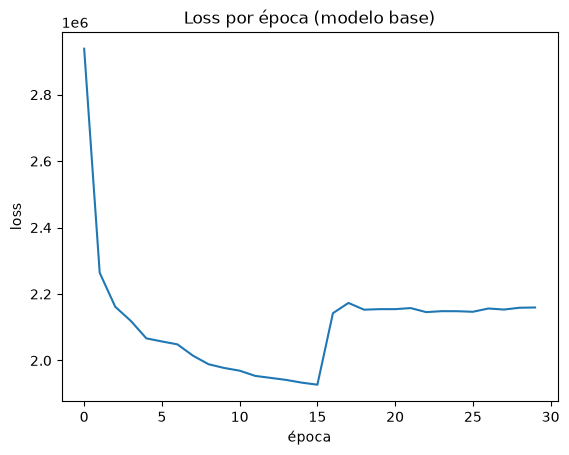

In [38]:
EPOCHS = 30

# Entrenamos el modelo generador de vectores
# Utilizamos nuestro callback
cb = callback()
w2v_model.train(sentence_tokens,
                total_examples=w2v_model.corpus_count,
                epochs=EPOCHS,
                compute_loss=True,
                callbacks=[cb])

plt.plot(cb.losses)
plt.xlabel("época"); plt.ylabel("loss"); plt.title("Loss por época (modelo base)")
plt.show()

**Interpretación del entrenamiento.** El loss del modelo base baja de ~2,9 millones a ~1,93 millones en las primeras 16 épocas y después salta a ~2,15 millones y queda plano. Ese salto no es el modelo empeorando: Gensim acumula el loss de todas las épocas en un número de 32 bits, y cuando el acumulado pasa los ~33,5 millones (2²⁵) pierde precisión al sumar valores chicos. Por eso el loss de Gensim sirve solo para ver la **tendencia** en las primeras épocas; la calidad de los embeddings la evaluamos con vecinos y analogías. Más abajo se grafica también el loss del modelo final.

#### Experimentos de hiperparámetros
El template de clase usa skip-gram con `window=2` y `vector_size=300`. Para justificar los valores que elegimos comparamos variantes cambiando **un hiperparámetro por vez**, con dos criterios:
- **Cualitativo:** los vecinos más cercanos de un conjunto fijo de palabras (modelo entrenado con la semilla 0).
- **Cuantitativo:** cuántas de 12 **analogías de selección** aparecen en el top-3 (ver sección 4 para la teoría de analogías). Cada variante se entrena con **3 semillas** y se informa la media y el desvío, para no sacar conclusiones de una sola corrida.

Estas analogías se usan solo para elegir el modelo. La evaluación de la sección 4 usa **otras** analogías, para no evaluar con los mismos datos con los que se eligió.

In [39]:
# (a, b, c, esperado): "a es a b como c es a esperado"
ANALOGIAS_SELECCION = [
    ("man", "woman", "he", "she"),
    ("man", "woman", "his", "her"),
    ("he", "she", "him", "her"),
    ("father", "mother", "son", "daughter"),
    ("man", "men", "woman", "women"),
    ("door", "doors", "window", "windows"),
    ("go", "went", "come", "came"),
    ("see", "saw", "know", "knew"),
    ("take", "took", "give", "gave"),
    ("day", "night", "morning", "evening"),
    ("small", "large", "short", "long"),
    ("one", "two", "three", "four"),
]
PALABRAS_PRUEBA = ["holmes", "watson", "murder", "london", "night", "door", "said"]
SEMILLAS = [0, 1, 2]
CONFIGURACIONES = {
    "skipgram w5 d100 (base)": dict(sg=1),
    "skipgram w2 d100": dict(sg=1, window=2),
    "skipgram w5 d300": dict(sg=1, vector_size=300),
    "cbow w5 d100": dict(sg=0),
    "cbow w2 d100": dict(sg=0, window=2),
}

def crear_y_entrenar(seed, **hiperparametros):
    modelo = crear_modelo(seed=seed, **hiperparametros)
    modelo.build_vocab(sentence_tokens)
    cb = callback(verbose=False)
    modelo.train(sentence_tokens, total_examples=modelo.corpus_count, epochs=EPOCHS,
                 compute_loss=True, callbacks=[cb])
    return modelo, cb.losses

def aciertos_analogias(modelo, analogias, topn=3):
    aciertos = 0
    for a, b, c, esperado in analogias:
        candidatos = [w for w, _ in modelo.wv.most_similar(positive=[b, c], negative=[a], topn=topn)]
        aciertos += esperado in candidatos
    return aciertos

variantes, losses, aciertos = {}, {}, {}
for nombre, hiperparametros in CONFIGURACIONES.items():
    aciertos[nombre] = []
    for seed in SEMILLAS:
        modelo, loss = crear_y_entrenar(seed, **hiperparametros)
        aciertos[nombre].append(aciertos_analogias(modelo, ANALOGIAS_SELECCION))
        if seed == SEMILLAS[0]:
            variantes[nombre], losses[nombre] = modelo, loss

tabla = pd.DataFrame({
    nombre: {w: ", ".join(x for x, _ in modelo.wv.most_similar(w, topn=4)) for w in PALABRAS_PRUEBA}
            | {"ANALOGÍAS (top-3, 3 semillas)": f"{np.mean(aciertos[nombre]):.1f} ± {np.std(aciertos[nombre]):.1f}  {aciertos[nombre]}"}
    for nombre, modelo in variantes.items()
})
with pd.option_context("display.max_colwidth", None):
    display(tabla.T)

,holmes,watson,murder,london,night,door,said,"ANALOGÍAS (top-3, 3 semillas)"
skipgram w5 d100 (base),"sherlock, heartily, stamford, he","dr, mortimer, doctor, awful","murderer, ryder, postmaster, escaped","order, devonshire, horsham, barrymores","day, morning, sounded, sell","unlocked, tap, slammed, curtain","answered, cried, remarked, exclaimed","5.7 ± 1.2 [6, 4, 7]"
skipgram w2 d100,"sherlock, wilson, mcmurdo, jones","mortimer, doctor, acknowledge, halloa","worst, murderer, importance, china","east, england, town, south","afternoon, day, ball, season","drawer, window, panel, latch","answered, exclaimed, stammered, gasped","4.3 ± 0.9 [5, 5, 3]"
skipgram w5 d300,"sherlock, stamford, sharply, rance","awful, bit, colleague, doctor","murderer, ryder, supposing, realize","north, order, devonshire, europe","sounded, 15, chronicle, morning","curtain, slammed, latch, panel","exclaimed, stammered, answered, murmured","2.3 ± 1.2 [4, 1, 2]"
cbow w5 d100,"wilson, holder, jones, merryweather","mortimer, roylott, doctor, roylott's","murderer, name, fortunes, narrative","order, town, south, england","day, afternoon, evening, morning","window, stairs, passage, stair","answered, remarked, cried, continued","9.3 ± 1.2 [9, 11, 8]"
cbow w2 d100,"wilson, lestrade, merryweather, jones","mortimer, roylott, doctor, grimesby","worst, family, name, fort","town, east, america, england","monday, day, afternoon, month","window, drawer, ventilator, table","answered, remarked, cried, continued","9.7 ± 0.5 [10, 9, 10]"


**Interpretación de los experimentos.**

- **Analogías de selección (top-3, media ± desvío en 3 semillas):** CBOW w2 = 9.7 ± 0.5, CBOW w5 = 9.3 ± 1.2, skip-gram base = 5.7 ± 1.2, skip-gram w2 = 4.3 ± 0.9, skip-gram d300 = 2.3 ± 1.2.
- **300 dimensiones (el valor del ejemplo) empeoran el modelo:** con las 3 semillas, la variante de 300 dimensiones acierta menos que la de 100. Con ~250 mil tokens hay demasiados parámetros para tan pocos datos.
- **CBOW supera a skip-gram** con las 3 semillas: el peor CBOW (8) acierta más que el mejor skip-gram (7).
- **Ventana 5 frente a 2 (el valor del ejemplo).** En analogías empatan: la diferencia (9.3 contra 9.7) es menor que la variación entre semillas. Desempatan los vecinos: con ventana 2 se vuelven más ruidosos (`murder → worst, family, name, fort`, `night → monday, day, afternoon, month`) que con ventana 5 (`murder → murderer, name, ...`, `night → day, afternoon, evening, morning`).

**Skip-gram frente a CBOW.** Según lo visto en clase:
- **CBOW** (*muchos a uno*: predice la palabra central a partir del contexto) es más rápido y funciona mejor con mucho texto y palabras comunes.
- **Skip-gram** (*uno a muchos*: predice el contexto a partir de la palabra) es más preciso con palabras raras y suele preferirse cuando el corpus no es muy grande.

Nuestro corpus es chico, así que la clase anticipa que debería ganar skip-gram. Con nuestros criterios ganó CBOW, pero hay que tener en cuenta **qué evaluamos**: las analogías y las palabras de prueba son **frecuentes** (pronombres, plurales, verbos comunes, `night`, `door`), que es justo donde CBOW rinde mejor. La ventaja de skip-gram está en las palabras raras, que este experimento no mide.

En la tabla también se observa una diferencia en el **tipo** de vecino, aunque solo con estas 7 palabras y una semilla, así que es una observación y no una conclusión firme:
- Skip-gram tiende a devolver palabras que **aparecen junto** a la consulta: `holmes → sherlock`, `door → unlocked, tap, slammed`.
- CBOW tiende a devolver palabras que **podrían reemplazarla** en la oración: `holmes → wilson, holder, jones`, `door → window, stairs, passage`, `night → day, afternoon, evening, morning`.

**Modelo final: CBOW, ventana 5, 100 dimensiones, `negative=20` (semilla 0).**

Vocabulario del modelo final: 3804


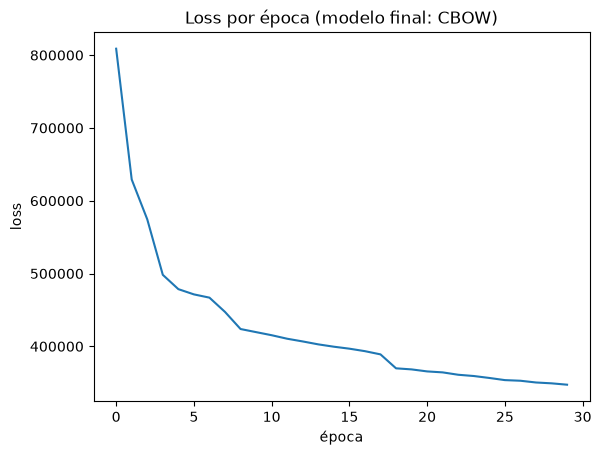

In [40]:
# Modelo final: CBOW, ventana 5, 100 dimensiones, semilla 0 (ver justificación arriba)
w2v_model = variantes["cbow w5 d100"]
print("Vocabulario del modelo final:", len(w2v_model.wv))

plt.plot(losses["cbow w5 d100"])
plt.xlabel("época"); plt.ylabel("loss"); plt.title("Loss por época (modelo final: CBOW)")
plt.show()

El loss del modelo final (CBOW) baja de forma monótona, de ~809 mil a ~347 mil, sin el salto del skip-gram: en CBOW el acumulado es menor (~12,7 millones) y no llega al límite de precisión.

### 4 - Ensayar
La similaridad entre palabras se mide con el **coseno** entre sus vectores, igual que en el Desafío 1, pero ahora los vectores son densos y pueden tener componentes negativas: el coseno va de -1 a 1.

Elegimos términos de interés del universo de Holmes: personajes (`holmes`, `watson`), crimen (`murder`), lugares (`london`), tiempo (`night`), objetos (`door`), emociones (`fear`) y verbos de habla (`said`).

In [41]:
# Palabras que MÁS se relacionan con...:
TERMINOS = ["holmes", "watson", "murder", "london", "night", "door", "fear", "said"]
for termino in TERMINOS:
    vecinos = w2v_model.wv.most_similar(positive=[termino], topn=6)
    print(f"{termino:8s} -> " + ", ".join(f"{w} ({s:.2f})" for w, s in vecinos))

holmes   -> wilson (0.59), holder (0.54), jones (0.53), merryweather (0.52), hatherley (0.49), rucastle (0.49)
watson   -> mortimer (0.63), roylott (0.57), doctor (0.54), roylott's (0.51), grimesby (0.46), i'll (0.44)
murder   -> murderer (0.58), name (0.47), fortunes (0.47), narrative (0.46), history (0.45), crime (0.44)
london   -> order (0.59), town (0.58), south (0.47), england (0.47), train (0.47), absence (0.45)
night    -> day (0.61), afternoon (0.56), evening (0.56), morning (0.50), week (0.47), bed (0.46)
door     -> window (0.74), stairs (0.58), passage (0.56), stair (0.56), carriage (0.56), loud (0.56)
fear     -> suspect (0.53), believe (0.52), think (0.52), lose (0.49), feel (0.48), fancy (0.48)
said     -> answered (0.83), remarked (0.74), cried (0.73), continued (0.67), asked (0.56), says (0.53)


In [42]:
# Palabras que MENOS se relacionan con...:
for termino in ["holmes", "murder", "night"]:
    lejanos = w2v_model.wv.most_similar(negative=[termino], topn=6)
    print(f"{termino:8s} -> " + ", ".join(f"{w} ({s:.2f})" for w, s in lejanos))

holmes   -> die (0.32), charming (0.29), discovered (0.29), missed (0.27), considered (0.27), fail (0.27)
murder   -> began (0.38), past (0.37), clapped (0.34), flying (0.33), downstairs (0.33), limp (0.33)
night    -> self (0.41), murderous (0.34), dying (0.34), whose (0.33), analytical (0.31), neglected (0.31)


In [43]:
# Ensayar con una palabra que no está en el vocabulario:
try:
    w2v_model.wv.most_similar("diedaa")
except KeyError as error:
    print("Error esperado:", error)

Error esperado: "Key 'diedaa' not present in vocabulary"


In [44]:
# el método `get_vector` permite obtener los vectores:
vector_holmes = w2v_model.wv.get_vector("holmes")
print(vector_holmes.shape)
print(vector_holmes[:10])

(100,)
[ 1.475691   -0.5086398  -2.6381261  -1.8144034   0.11824554  3.2832556
  1.1264131   1.7031409  -0.35312918  1.2235118 ]


In [45]:
# el método `most_similar` también permite comparar a partir de vectores
w2v_model.wv.most_similar(vector_holmes, topn=5)

[('holmes', 1.0),
 ('wilson', 0.5903424024581909),
 ('holder', 0.5385756492614746),
 ('jones', 0.5315796136856079),
 ('merryweather', 0.5185688734054565)]

**Interpretación de las similitudes.**

- **`holmes`** se acerca a `wilson`, `holder`, `jones`, `merryweather`: otros **apellidos** que el texto usa igual que a Holmes ("said Mr. Wilson", "said Holmes"). Son palabras que pueden reemplazarse entre sí en la oración; `mr` no aparece entre los vecinos porque acompaña al apellido, no lo reemplaza.
- **`watson`** se acerca a `mortimer`, `roylott`, `doctor`, `grimesby`: los **otros médicos** de los libros (Dr. Mortimer, Dr. Grimesby Roylott). Comparten el contexto "Dr. ___", que la ventana ve gracias a que no cortamos la oración en las abreviaturas (sección 1). El embedding refleja **cómo se usa la palabra en el corpus**, no quién es el personaje: Watson es el narrador, y casi solo se lo nombra con su título o cuando otro le habla.
- **`fear`** se acerca a `suspect`, `believe`, `think`, `feel`: en estos libros se usa como verbo mental ("I fear that...", equivalente a "I suspect that..."), no como emoción.
- **Casos con buena semántica:** `murder → murderer, crime`; `london → town, england, train`; `door → window` (0.74); `said → answered, remarked, cried` (0.73 a 0.83); `night → day, afternoon, evening, morning`.
- **Ruido:** algunos vecinos no tienen relación de significado (`london → order, absence`, `murder → name, fortunes`). Con un corpus chico, una coincidencia de contextos en pocas oraciones alcanza para acercar dos palabras.
- **"Menos similares":** `most_similar(negative=[w])` busca las palabras más cercanas al vector `-w`. El valor 0.32 de `holmes → die` significa coseno ≈ -0.32 con `holmes`. Son palabras sin relación clara entre sí: **lo opuesto en el espacio no es un antónimo** ni tiene significado semántico.

#### Tests de analogías
Si los embeddings capturan relaciones, éstas deberían aparecer como **direcciones** en el espacio: el vector `woman - man` representaría "masculino → femenino". Entonces `he + (woman - man)` debería quedar cerca de `she`. En Gensim:

```python
most_similar(positive=["woman", "he"], negative=["man"])   # man : woman :: he : ?
```

Evaluamos el modelo final con **12 analogías de prueba**, distintas de las 12 que usamos para elegirlo: género, plural, tiempo verbal (pasado), comparativos y posesivos.

In [46]:
# Analogías de prueba: no se usaron para elegir el modelo
ANALOGIAS_PRUEBA = [
    ("husband", "wife", "brother", "sister"),
    ("boy", "girl", "man", "woman"),
    ("mr", "mrs", "he", "she"),
    ("i", "my", "we", "our"),
    ("hand", "hands", "eye", "eyes"),
    ("room", "rooms", "house", "houses"),
    ("walk", "walked", "look", "looked"),
    ("tell", "told", "hear", "heard"),
    ("think", "thought", "feel", "felt"),
    ("run", "ran", "sit", "sat"),
    ("speak", "spoke", "write", "wrote"),
    ("good", "better", "bad", "worse"),
]

filas = []
for a, b, c, esperado in ANALOGIAS_PRUEBA:
    candidatos = [w for w, _ in w2v_model.wv.most_similar(positive=[b, c], negative=[a], topn=3)]
    filas.append({"analogía": f"{a} : {b} :: {c} : ?", "esperado": esperado,
                  "top-3": ", ".join(candidatos),
                  "resultado": "top-1" if candidatos[0] == esperado else ("top-3" if esperado in candidatos else "falla")})
analogias_df = pd.DataFrame(filas)
display(analogias_df)
print(analogias_df["resultado"].value_counts().to_dict())

,analogía,esperado,top-3,resultado
0,husband : wife :: brother : ?,sister,"sister, son, uncle",top-1
1,boy : girl :: man : ?,woman,"woman, lady, lad",top-1
2,mr : mrs :: he : ?,she,"she, barrymore, baronet",top-1
3,i : my :: we : ?,our,"our, gradually, his",top-1
4,hand : hands :: eye : ?,eyes,"fingers, brows, wrists",falla
5,room : rooms :: house : ?,houses,"houses, quest, lines",top-1
6,walk : walked :: look : ?,looked,"looked, gazed, glanced",top-1
7,tell : told :: hear : ?,heard,"heard, reached, recovered",top-1
8,think : thought :: feel : ?,felt,"speak, felt, meant",top-3
9,run : ran :: sit : ?,sat,"halfway, rug, road",falla


{'top-1': 7, 'falla': 4, 'top-3': 1}


In [47]:
# Analogías propias del dominio Holmes
for a, b, c in [("holmes", "detective", "lestrade"), ("brother", "sister", "father"), ("light", "dark", "day")]:
    try:
        print(f"{a} : {b} :: {c} : ? ->", [w for w, _ in w2v_model.wv.most_similar(positive=[b, c], negative=[a], topn=3)])
    except KeyError as error:
        print(f"{a} : {b} :: {c} : ? -> {error}")

holmes : detective :: lestrade : ? -> ['earnestly', 'jones', 'servant']
brother : sister :: father : ? -> ['heart', 'mother', 'wife']
light : dark :: day : ? -> ['evening', 'busy', 'bad']


**Interpretación de las analogías.**

Con las 12 analogías de prueba, **7 aciertan en top-1 y 1 más en top-3**; 4 fallan. Es algo menos que con las analogías de selección (9 de 12 en top-3 para este mismo modelo), lo esperable: el modelo se eligió por su puntaje en aquellas, y estas miden mejor cómo generaliza.

- **Aciertos:** género (`husband:wife :: brother:sister`, `boy:girl :: man:woman`, `mr:mrs :: he:she`), posesivos (`i:my :: we:our`), plural (`room → houses`) y pasado regular o muy frecuente (`look → looked`, `hear → heard`). `feel → felt` queda en el top-3.
- **Fallas con un patrón:**
  - `hand:hands :: eye:?` devuelve `fingers`, `brows`, `wrists`: captura "partes del cuerpo en plural", pero no la palabra exacta.
  - `speak:spoke :: write:?` devuelve `stepped`, `stole`, `walked`: captura "verbo en pasado".
  - `good:better :: bad:?` devuelve `less`, `more`: captura "comparativo".
  - `run:ran :: sit:?` falla sin un patrón claro.
  Las relaciones irregulares (`wrote`, `worse`, `sat`) son más difíciles: cada una aparece pocas veces y no comparte la forma de las demás.
- **Las del dominio Holmes:**
  - `holmes:detective :: lestrade:?` devuelve `jones` en el top-3. Athelney Jones es otro inspector de Scotland Yard, como Lestrade: captura el rol policial, aunque no la palabra "inspector".
  - `brother:sister :: father:?` encuentra `mother` en el top-3.
  - `light:dark :: day:?` devuelve `evening` en top-1.

Con ~250 mil tokens el modelo aprende bien las regularidades frecuentes; las relaciones irregulares o semánticas finas necesitan mucho más texto.

### 5 - Visualizar agrupación de vectores
Los vectores tienen 100 dimensiones; para verlos hay que proyectarlos a 2D.

- **PCA** es una proyección lineal que conserva la varianza global.
- **t-SNE** es no lineal y conserva **vecindarios locales**: palabras cercanas en 100D quedan cercanas en 2D. Es ideal para ver grupos, pero las distancias *entre* grupos y el tamaño de los grupos no tienen significado.

Aplicamos t-SNE sobre todo el vocabulario y graficamos solo las `MAX_WORDS` palabras más frecuentes (`index_to_key` está ordenado por frecuencia), excluyendo *stopwords* (the, of, and...), que ocupan el gráfico sin formar grupos interesantes.

In [48]:
from sklearn.manifold import TSNE

def reduce_dimensions(model, num_dimensions = 2 ):

    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)

    tsne = TSNE(n_components=num_dimensions, random_state=0)
    vectors = tsne.fit_transform(vectors)

    return vectors, labels

In [49]:
# Graficar los embedddings en 2D
import plotly.express as px
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# 200 palabras: suficientes para que aparezcan grupos, pocas para que las etiquetas se lean
MAX_WORDS = 200

vecs, labels = reduce_dimensions(w2v_model)
indices = [i for i, w in enumerate(labels) if w not in ENGLISH_STOP_WORDS][:MAX_WORDS]

fig = px.scatter(x=vecs[indices, 0], y=vecs[indices, 1], text=labels[indices])
fig.update_traces(textposition="top center", marker_size=4)
fig.show()

In [50]:
# Graficar los embedddings en 3D
vecs_3d, labels_3d = reduce_dimensions(w2v_model, 3)

fig = px.scatter_3d(x=vecs_3d[indices, 0], y=vecs_3d[indices, 1], z=vecs_3d[indices, 2], text=labels_3d[indices])
fig.update_traces(marker_size=2)
fig.show()

**Interpretación de los grupos.**

Inspeccionando el gráfico 2D encontramos los siguientes grupos. Cada captura amplía la zona del gráfico donde está el grupo (en rojo las palabras del grupo, en azul otras palabras graficadas de esa zona). Como el entrenamiento es reproducible (`REPRODUCIBLE = True`) y t-SNE usa `random_state=0`, el gráfico es el mismo en cada ejecución.

**Verbos de habla:** `said, asked, cried, answered, remarked`

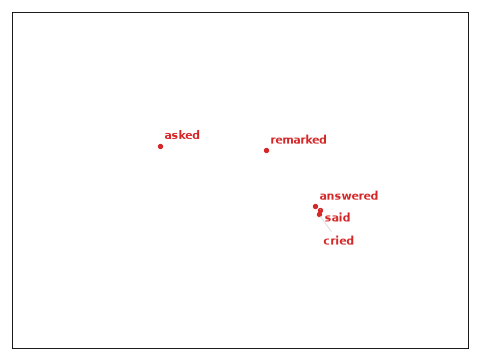

Introducen diálogos y siempre aparecen en el mismo patrón (`"...," said Holmes`). `said`, `cried` y `answered` quedan prácticamente superpuestos.

**Verbos de acción en pasado:** `came, went, walked, stood, sat, turned, looked, followed`

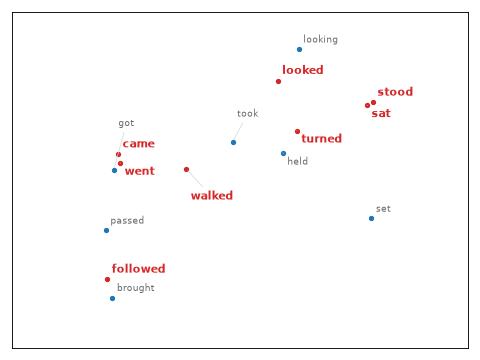

Narración en pasado de movimientos ("he walked to the door"). Alrededor aparecen otros pasados (`took, held, passed, got`). `stood` y `sat` quedan juntos: describen la postura; `came` y `went`, la dirección.

**Partes del día:** `night, day, morning, evening`

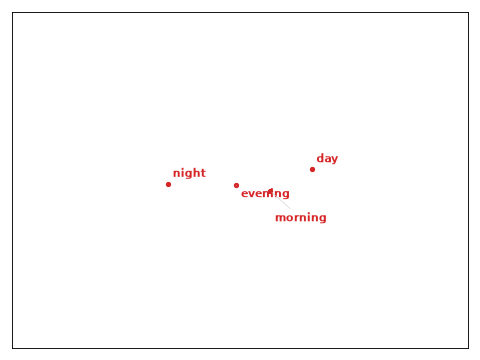

Aparecen en las mismas construcciones ("that night", "in the morning").

**Partes del cuerpo:** `face, eyes, hand, hands, head, feet` (y `chair`)

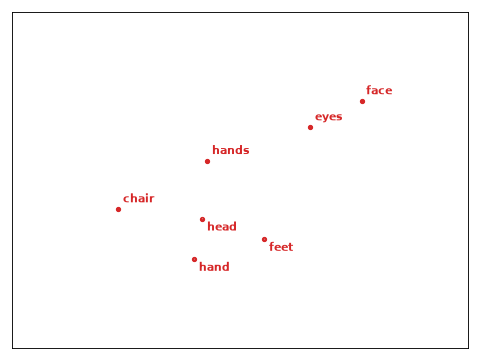

Descripciones de personas: "his face", "her eyes", "in his hand". `chair` se suma porque comparte las mismas preposiciones ("in his chair").

**Colores y tamaños:** `black, white, red, dark, light, small, large, high, heavy`

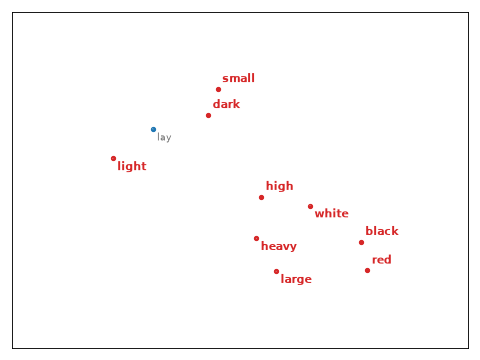

Adjetivos que modifican a los mismos sustantivos ("a large black box").

**Lugares y objetos de la casa:** `room, door, window, table, road, moor`

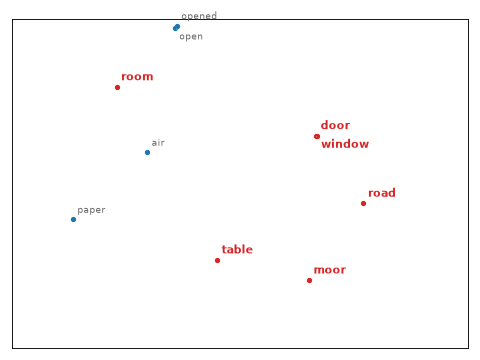

Lugares por donde se mueven los personajes. `door` y `window` quedan superpuestas: son casi intercambiables en el texto ("opened the door/window").

**Personas:** `man, woman, lady, fellow`

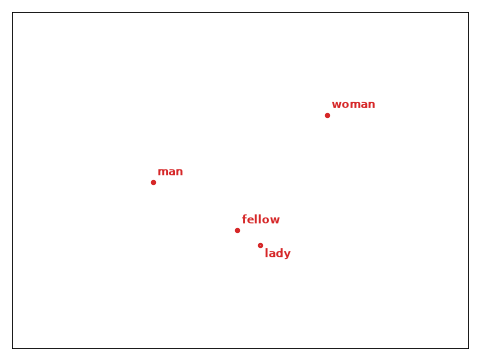

Sustantivos genéricos para referirse a alguien ("a tall man", "the lady").

**Apellidos y tratamientos:** `holmes, lestrade, stapleton, mr, mrs`

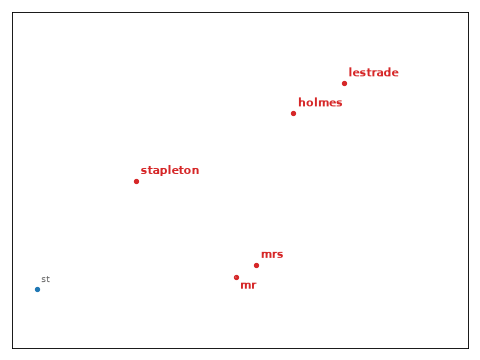

Personajes que se nombran por el apellido, junto a los tratamientos que los preceden. Esta zona depende de no cortar la oración después de `Mr.` (sección 1).

**Los doctores:** `watson, mortimer, dr`

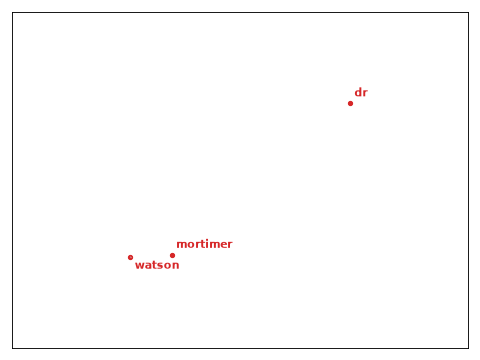

Watson y Mortimer, los dos médicos de *El sabueso de los Baskerville*, quedan superpuestos, con `dr` al lado. Es el mismo efecto que se vio con `most_similar("watson")`.

**Qué muestran los grupos.** Casi todos son **categorías gramaticales o funcionales** (verbos de habla, verbos de movimiento en pasado, adjetivos, sustantivos de lugar, apellidos), no temas: la ventana de contexto agrupa palabras que cumplen el mismo rol en la oración. Como se vio en clase, t-SNE sirve solo como herramienta exploratoria: la distancia *entre* grupos no tiene significado.

In [52]:
# También se pueden guardar los vectores y labels como tsv para graficar en
# http://projector.tensorflow.org/


vectors = np.asarray(w2v_model.wv.vectors)
labels = list(w2v_model.wv.index_to_key)

np.savetxt("vectors.tsv", vectors, delimiter="\t")

with open("labels.tsv", "w") as fp:
    for item in labels:
        fp.write("%s\n" % item)

### 6 - Conclusiones

1. **Corpus y preprocesamiento.** Cuatro novelas de Holmes (~250 mil tokens, 3.804 palabras en el vocabulario con `min_count=5`, frente a 445 del ejemplo de Beatles) alcanzan para obtener embeddings con estructura interpretable. La segmentación importa: descartamos títulos e índices, y evitamos que `Mr.` o `Dr.` corten la oración. Gracias a eso, `watson` se agrupa con los otros médicos (`mortimer`, `roylott`).
2. **Qué captura Word2Vec.** Agrupa palabras **intercambiables** en el mismo contexto: verbos de habla, partes del cuerpo, apellidos. En el Desafío 1, la co-ocurrencia por documento capturaba **tema** (`car → dealer`). La ventana de contexto produce una similaridad más gramatical y funcional, como se ve también en los grupos del t-SNE.
3. **Skip-gram frente a CBOW.** La clase indica que skip-gram suele preferirse con corpus chicos por su precisión en palabras raras. En nuestra evaluación, con palabras frecuentes, CBOW ganó con las 3 semillas. La elección depende de qué palabras interesan.
4. **Otros hiperparámetros** (comparados con 3 semillas):
   - `negative=20`: alto, como se recomienda para corpus pequeños.
   - 300 dimensiones empeoraron el modelo con todas las semillas, por falta de datos.
   - Las ventanas 2 y 5 empataron en analogías; elegimos 5 por la calidad de los vecinos.
5. **Los embeddings reflejan el uso en el corpus, no el conocimiento del mundo.** `watson` se parece a otros doctores por el contexto "Dr. ___", y `fear` a verbos mentales porque se usa como "I fear that...".
6. **"Menos similares".** Las palabras más cercanas a `-w` no tienen relación semántica interpretable: lo opuesto en el espacio no es un antónimo.
7. **Analogías.** Evaluadas con analogías distintas de las usadas para elegir el modelo, las relaciones gramaticales frecuentes (género, posesivos, pasado regular) funcionan. Las irregulares (`wrote`, `worse`) fallan, aunque el modelo suele encontrar la categoría correcta.
8. **Limitaciones.** El corpus es chico (hay palabras importantes con pocas apariciones, como `detective` o `mother`), cada palabra tiene un único vector sin distinguir sentidos, y el loss que informa Gensim pierde precisión en entrenamientos largos.